# F-DATA — Analisi e regressione sui job di Fugaku

Dataset: [F-DATA](https://doi.org/10.5281/zenodo.11467483), un file `YY_MM.parquet` per ogni mese (marzo 2021 – aprile 2024).
Descrizione delle colonne: `docs/feature_list.md`.

## Cell 00 : Imports

In [2]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error, r2_score)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (10, 4)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("pandas", pd.__version__, "| numpy", np.__version__, "| torch", torch.__version__)

pandas 1.5.3 | numpy 1.23.5 | torch 2.14.1+cu130


## Cell 01 : Load

I file di F-DATA sono `.parquet` (non CSV): si leggono con `pd.read_parquet`. La funzione accetta anche `.csv`, se nella cartella ci sono file in quel formato.

La colonna `embedding` (un vettore di float per job) non viene caricata: sull'intero dataset occuperebbe decine di GB di RAM e non serve agli esperimenti.
`SAMPLE_PER_FILE` limita le righe prese da ogni mese; mettilo a `None` per caricare tutto.

In [4]:
DATA_DIR = Path.home() / "Desktop/xpd_cfd_bot/F-DATA/F-DATA/F-DATA"
MONTHS = None              # None = tutti i mesi presenti, oppure es. ["21_04", "21_05"]
SAMPLE_PER_FILE = 20_000   # righe campionate per mese; None = tutte

COLS = [
    "jid", "usr", "jnam", "cnumr", "cnumat", "cnumut", "nnumr", "adt", "qdt", "schedsdt", "deldt",
    "ec", "elpl", "sdt", "edt", "nnuma", "idle_time_ave", "nnumu",
    "perf1", "perf2", "perf3", "perf4", "perf5", "perf6",
    "mszl", "pri", "econ", "avgpcon", "minpcon", "maxpcon", "msza", "mmszu",
    "uctmut", "sctmut", "usctmut", "jobenv_req", "freq_req", "freq_alloc",
    "flops", "mbwidth", "opint", "pclass", "exit state", "duration",
]

def load_month(path):
    if path.suffix == ".csv":
        df = pd.read_csv(path, usecols=lambda c: c in COLS)
    else:
        df = pd.read_parquet(path, columns=COLS)
    if SAMPLE_PER_FILE and len(df) > SAMPLE_PER_FILE:
        df = df.sample(SAMPLE_PER_FILE, random_state=SEED)
    df["month"] = path.stem
    return df

files = sorted(p for p in DATA_DIR.iterdir() if p.suffix in (".parquet", ".csv"))
if MONTHS:
    files = [p for p in files if p.stem in MONTHS]
assert files, f"Nessun file .parquet/.csv in {DATA_DIR.resolve()}"

t0 = time.time()
df = pd.concat([load_month(p) for p in files], ignore_index=True)
print(f"{len(files)} file caricati in {time.time() - t0:.1f}s -> {df.shape[0]:,} righe x {df.shape[1]} colonne")

38 file caricati in 42.3s -> 760,000 righe x 45 colonne


## Cell 02 : Check

Controllo del caricamento: struttura, tipi (formatter), valori mancanti, duplicati, coerenza delle date.
Le colonne temporali vengono convertite in `datetime64`.

In [5]:
print("Shape:", df.shape)
print("Mesi:", df["month"].nunique(), "->", df["month"].min(), "...", df["month"].max())
print(f"Memoria: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
df.head()

Shape: (760000, 45)
Mesi: 38 -> 21_03 ... 24_04
Memoria: 910 MB


,jid,usr,jnam,cnumr,cnumat,cnumut,nnumr,adt,qdt,schedsdt,deldt,ec,elpl,sdt,edt,nnuma,idle_time_ave,nnumu,perf1,perf2,perf3,perf4,perf5,perf6,mszl,pri,econ,avgpcon,minpcon,maxpcon,msza,mmszu,uctmut,sctmut,usctmut,jobenv_req,freq_req,freq_alloc,flops,mbwidth,opint,pclass,exit state,duration,month
0,jid_184809,usr_195,jnam_31435,48,48,48,1,2021-03-09 17:43:31+09,2021-03-09 17:43:31+09,2021-03-11 20:44:48+09,1970-01-01 09:00:00+09,0,21600.0,2021-03-11 20:45:28+09,2021-03-11 21:35:04+09,1,1734.729549,1,1.191620e+14,2.244580e+12,4.886890e+13,6.155344e+11,4.338539e+11,0.0,1.844674e+19,127,92.940631,111.403750,108.987311,111.716209,18446744073709551615,6.810960e+09,64564340.0,62726870.0,127291210.0,jobenv_req_0,2000,2000,1.592886e+11,1.803551e+10,8.831939,compute-bound,completed,2976.0,21_03
1,jid_458497,usr_180,jnam_42094,48,48,48,1,2021-03-20 15:09:13+09,2021-03-20 15:09:13+09,2021-03-20 15:09:13+09,1970-01-01 09:00:00+09,0,3000.0,2021-03-20 15:09:47+09,2021-03-20 15:23:42+09,1,332.327819,1,4.835253e+13,4.260725e+13,4.387212e+10,7.550269e+10,5.378882e+10,0.0,1.844674e+19,127,26.608147,111.519902,105.645080,114.219676,18446744073709551615,1.418658e+09,25813730.0,2470910.0,28284640.0,jobenv_req_0,2000,2000,8.494163e+10,5.476219e+09,15.511000,compute-bound,completed,836.0,21_03
2,jid_81942,usr_195,jnam_1717,48,48,48,1,2021-03-05 11:37:18+09,2021-03-05 11:37:18+09,2021-03-05 12:11:03+09,1970-01-01 09:00:00+09,1,14400.0,2021-03-05 12:11:14+09,2021-03-05 12:41:23+09,1,910.364370,1,8.636502e+13,1.326111e+12,2.586923e+13,4.468231e+11,2.763472e+11,0.0,1.844674e+19,127,56.895511,113.155780,111.562248,121.082279,18446744073709551615,4.796383e+09,47355070.0,33892440.0,81247510.0,jobenv_req_0,2000,2000,1.164950e+11,1.714876e+10,6.793202,compute-bound,failed,1810.0,21_03
3,jid_187575,usr_9,jnam_10,36864,36864,2014,768,2021-03-11 22:35:32+09,2021-03-11 22:35:32+09,2021-03-11 22:35:32+09,1970-01-01 09:00:00+09,0,180.0,2021-03-11 22:35:48+09,2021-03-11 22:36:27+09,768,39.995838,768,3.106511e+11,6.181180e+05,0.000000e+00,2.755214e+08,2.506775e+08,0.0,1.844674e+19,127,1117.721560,82523.743992,82523.743992,82523.743992,18446744073709551615,2.936013e+08,99530.0,72460.0,171990.0,jobenv_req_0,2000,2000,1.485020e+08,2.696930e+12,0.000055,memory-bound,completed,40.0,21_03
4,jid_483841,usr_195,jnam_36081,48,48,48,1,2021-03-15 00:44:12+09,2021-03-15 00:44:12+09,2021-03-20 21:37:05+09,1970-01-01 09:00:00+09,0,36000.0,2021-03-20 21:37:30+09,2021-03-20 23:26:59+09,1,2908.189877,1,3.515338e+14,3.311333e+12,6.736502e+13,1.259664e+12,7.366622e+11,0.0,1.844674e+19,127,211.039437,115.624929,111.224867,124.270302,18446744073709551615,1.469035e+10,199899030.0,102921120.0,302820150.0,jobenv_req_0,2000,2000,7.449087e+10,1.163039e+10,6.404846,compute-bound,completed,6570.0,21_03


In [6]:
DATE_COLS = ["adt", "qdt", "schedsdt", "deldt", "sdt", "edt"]
print("Tipi prima della conversione:")
print(df[DATE_COLS].dtypes.to_string())

for c in DATE_COLS:
    n_before = df[c].notna().sum()
    df[c] = pd.to_datetime(df[c], errors="coerce")
    lost = n_before - df[c].notna().sum()
    if lost:
        print(f"  {c}: {lost} valori non convertibili -> NaT")

print("\nTipi dopo la conversione:")
print(df[DATE_COLS].dtypes.to_string())

Tipi prima della conversione:
adt         object
qdt         object
schedsdt    object
deldt       object
sdt         object
edt         object

Tipi dopo la conversione:
adt         datetime64[ns, pytz.FixedOffset(540)]
qdt         datetime64[ns, pytz.FixedOffset(540)]
schedsdt    datetime64[ns, pytz.FixedOffset(540)]
deldt       datetime64[ns, pytz.FixedOffset(540)]
sdt         datetime64[ns, pytz.FixedOffset(540)]
edt         datetime64[ns, pytz.FixedOffset(540)]


In [7]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 760000 entries, 0 to 759999
Data columns (total 45 columns):
 #   Column         Non-Null Count   Dtype                                
---  ------         --------------   -----                                
 0   jid            760000 non-null  object                               
 1   usr            760000 non-null  object                               
 2   jnam           760000 non-null  object                               
 3   cnumr          760000 non-null  int64                                
 4   cnumat         760000 non-null  int64                                
 5   cnumut         760000 non-null  int64                                
 6   nnumr          760000 non-null  int64                                
 7   adt            760000 non-null  datetime64[ns, pytz.FixedOffset(540)]
 8   qdt            760000 non-null  datetime64[ns, pytz.FixedOffset(540)]
 9   schedsdt       760000 non-null  datetime64[ns, pytz.FixedOf

In [8]:
nulls = df.isna().sum()
print("Valori mancanti per colonna (solo > 0):")
print(nulls[nulls > 0].sort_values(ascending=False).to_string())
print("\nJob duplicati (stesso jid):", df.duplicated("jid").sum())
print("\nexit state:\n", df["exit state"].value_counts(dropna=False).to_string())
print("\npclass:\n", df["pclass"].value_counts(dropna=False).to_string())

Valori mancanti per colonna (solo > 0):
Series([], )

Job duplicati (stesso jid): 148708

exit state:
 completed    684146
failed        75854

pclass:
 memory-bound     472900
compute-bound    287100


In [9]:
# Coerenza temporale: arrivo <= inizio <= fine
checks = {
    "sdt < adt (inizio prima dell'arrivo)": (df["sdt"] < df["adt"]).sum(),
    "edt < sdt (fine prima dell'inizio)": (df["edt"] < df["sdt"]).sum(),
    "sdt mancante": df["sdt"].isna().sum(),
    "edt mancante": df["edt"].isna().sum(),
}
pd.Series(checks, name="righe")

sdt < adt (inizio prima dell'arrivo)    0
edt < sdt (fine prima dell'inizio)      0
sdt mancante                            0
edt mancante                            0
Name: righe, dtype: int64

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
cnumr,760000.0,2.220067e+03,3.695275e+04,4.800000e+01,4.800000e+01,4.800000e+01,3.840000e+02,7.299072e+06
cnumat,760000.0,2.220064e+03,3.695275e+04,4.800000e+01,4.800000e+01,4.800000e+01,3.840000e+02,7.299072e+06
cnumut,760000.0,1.905247e+03,3.409468e+04,3.000000e+00,4.800000e+01,4.800000e+01,2.680000e+02,7.299072e+06
nnumr,760000.0,4.625139e+01,7.698490e+02,1.000000e+00,1.000000e+00,1.000000e+00,8.000000e+00,1.520640e+05
ec,760000.0,1.728101e+00,1.838679e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.550000e+02
elpl,760000.0,3.360946e+04,5.826468e+04,1.000000e+01,2.700000e+03,7.200000e+03,4.320000e+04,5.184000e+05
nnuma,760000.0,5.263975e+01,7.900644e+02,1.000000e+00,1.000000e+00,1.000000e+00,1.200000e+01,1.520640e+05
idle_time_ave,760000.0,2.652246e+03,9.011023e+03,5.465360e-01,6.626401e+01,4.359586e+02,1.609303e+03,2.524571e+05
nnumu,760000.0,4.407508e+01,7.646043e+02,1.000000e+00,1.000000e+00,1.000000e+00,6.000000e+00,1.520640e+05
perf1,760000.0,2.209297e+16,4.313311e+17,1.828471e+08,2.435479e+12,1.454494e+14,1.612381e+15,1.176518e+20


## Cell 03 : Analysis

### 03.1 Duration da DateTime

La durata viene ricalcolata come `t_finish - t_start` (`edt - sdt`) in secondi e confrontata con la colonna `duration` del dataset.

In [11]:
df["duration_s"] = (df["edt"] - df["sdt"]).dt.total_seconds()
df["wait_s"] = (df["sdt"] - df["adt"]).dt.total_seconds()

diff = (df["duration_s"] - df["duration"]).abs()
print(df[["duration", "duration_s", "wait_s"]].describe().T)
print(f"\n|duration_s - duration| > 1s: {(diff > 1).sum():,} job ({(diff > 1).mean():.2%})")

               count          mean            std  min    25%     50%      75%        max
duration    760000.0   9524.469459   22072.046868  1.0  143.0  1331.0   7908.0   259201.0
duration_s  760000.0   9523.987400   22072.043506  0.0  143.0  1330.0   7907.0   259201.0
wait_s      760000.0  42475.507932  161680.913110  4.0   58.0  1628.0  25205.0  9632763.0

|duration_s - duration| > 1s: 10 job (0.00%)


### 03.2 Distribuzioni delle colonne interessanti

`avgpcon` è la potenza media **per nodo**; la potenza del job intero è stimata come `avgpcon × nnumu`.
Gli assi x sono logaritmici perché le distribuzioni sono molto asimmetriche.

Potenza media per nodo (avgpcon): 4963.18  | mediana 115.54
Potenza media per job (avgpcon x nnumu): 64821718.77  | mediana 117.02


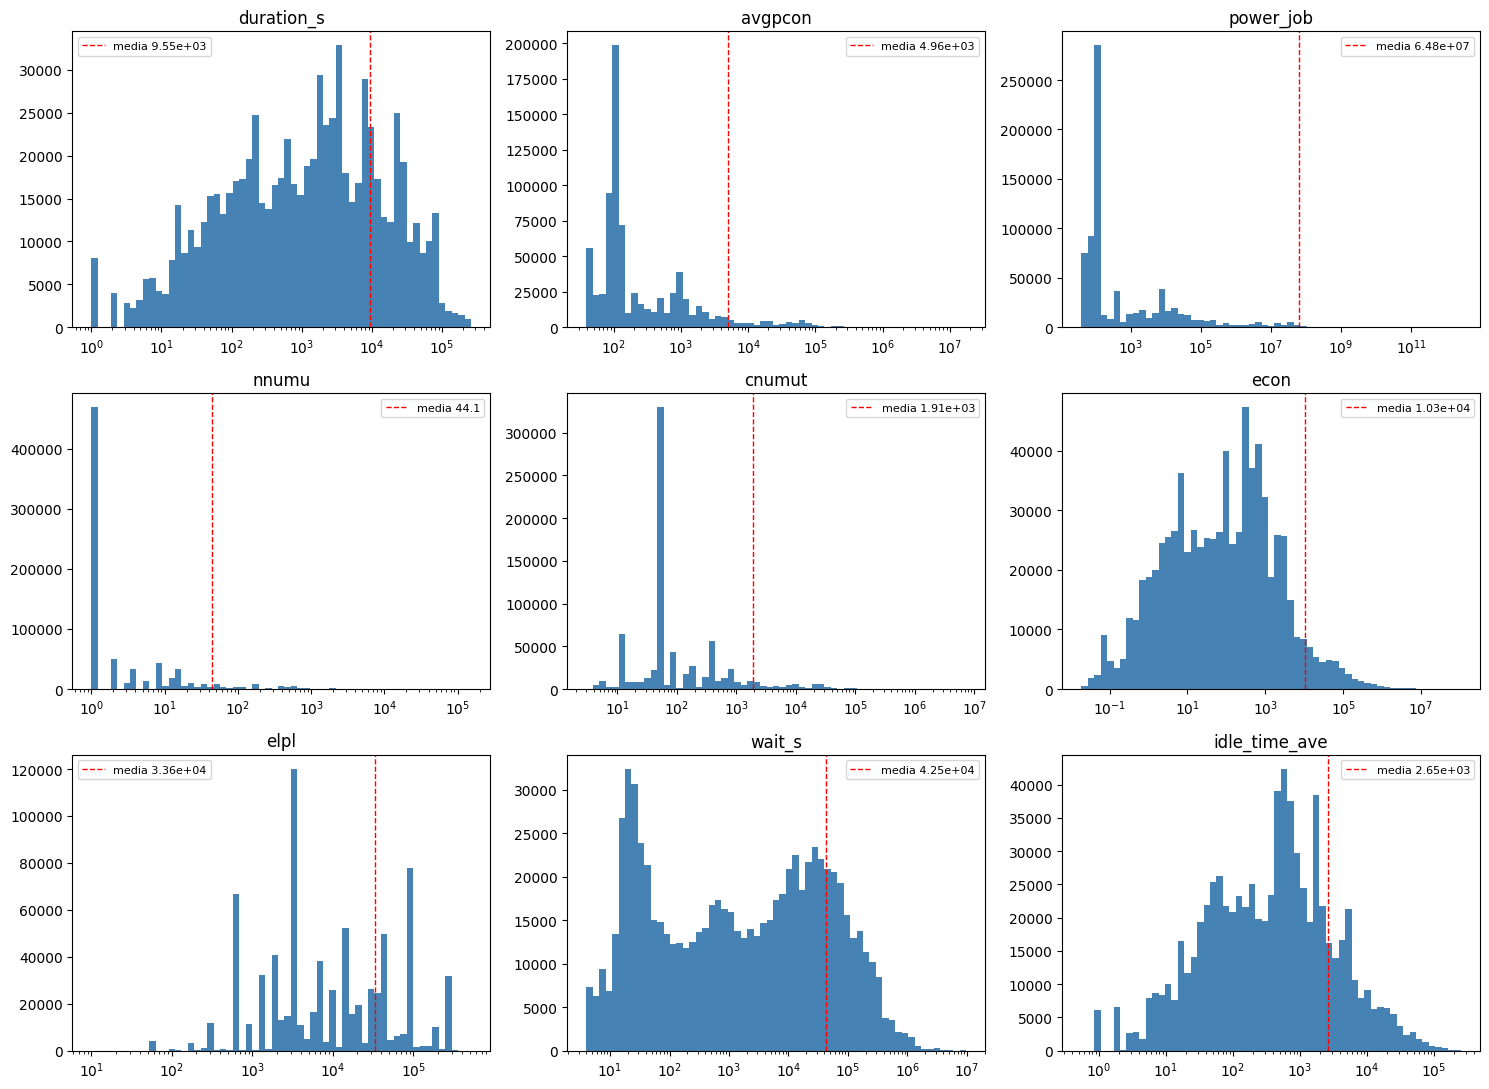

In [12]:
df["power_job"] = df["avgpcon"] * df["nnumu"]

print(f"Potenza media per nodo (avgpcon): {df['avgpcon'].mean():.2f}  | mediana {df['avgpcon'].median():.2f}")
print(f"Potenza media per job (avgpcon x nnumu): {df['power_job'].mean():.2f}  | mediana {df['power_job'].median():.2f}")

COLS_DIST = ["duration_s", "avgpcon", "power_job", "nnumu", "cnumut", "econ", "elpl", "wait_s", "idle_time_ave"]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), COLS_DIST):
    v = df[c].dropna()
    v = v[v > 0]
    ax.hist(v, bins=np.logspace(np.log10(v.min()), np.log10(v.max()), 60), color="steelblue")
    ax.set_xscale("log")
    ax.set_title(c)
    ax.axvline(v.mean(), color="red", ls="--", lw=1, label=f"media {v.mean():.3g}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 03.3 Potenza in relazione a nodi, core e durata

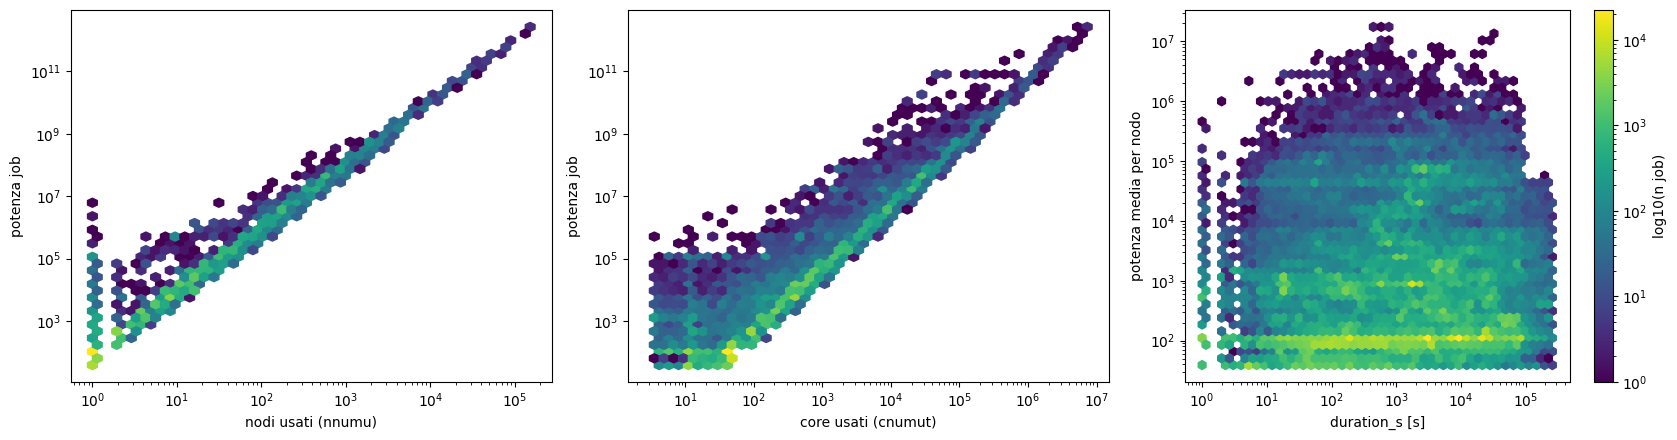

In [13]:
def hexplot(ax, x, y, xl, yl):
    m = (df[x] > 0) & (df[y] > 0)
    hb = ax.hexbin(df.loc[m, x], df.loc[m, y], xscale="log", yscale="log", gridsize=45, bins="log", cmap="viridis")
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    return hb

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
hexplot(axes[0], "nnumu", "power_job", "nodi usati (nnumu)", "potenza job")
hexplot(axes[1], "cnumut", "power_job", "core usati (cnumut)", "potenza job")
hb = hexplot(axes[2], "duration_s", "avgpcon", "duration_s [s]", "potenza media per nodo")
fig.colorbar(hb, ax=axes[2], label="log10(n job)")
plt.tight_layout()
plt.show()

,n_job,avgpcon_media,power_job_media,duration_media_s
nnumu,,,,
"(0.0, 1.0]",469109,320.838707,3.208387e+02,8251.020479
"(1.0, 2.0]",49685,205.766632,4.115333e+02,22727.172285
"(2.0, 4.0]",42036,408.147617,1.564881e+03,13325.150086
"(4.0, 8.0]",58583,797.481570,6.049993e+03,5621.290135
"(8.0, 16.0]",57190,1613.123683,2.201697e+04,8863.542088
"(16.0, 64.0]",41886,3506.318318,1.377174e+05,12102.810820
"(64.0, 256.0]",20648,16137.446661,2.773285e+06,8243.416118
"(256.0, 1024.0]",17022,60061.544812,3.536986e+07,7844.181177
"(1024.0, inf]",3841,508386.793144,1.265232e+10,8168.924759


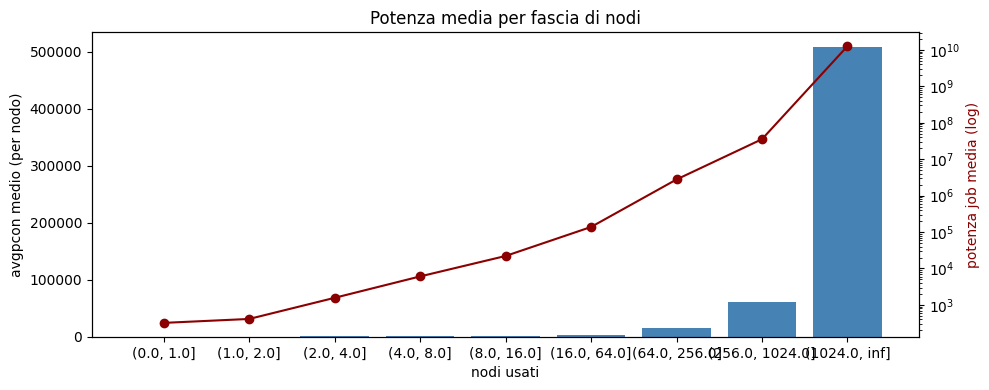

In [14]:
# Potenza media per fascia di nodi usati
node_bins = [0, 1, 2, 4, 8, 16, 64, 256, 1024, np.inf]
grp = df.groupby(pd.cut(df["nnumu"], node_bins))
summary_nodes = grp.agg(n_job=("avgpcon", "size"),
                        avgpcon_media=("avgpcon", "mean"),
                        power_job_media=("power_job", "mean"),
                        duration_media_s=("duration_s", "mean"))
display(summary_nodes)

fig, ax1 = plt.subplots(figsize=(10, 4))
x = summary_nodes.index.astype(str)
ax1.bar(x, summary_nodes["avgpcon_media"], color="steelblue")
ax1.set_ylabel("avgpcon medio (per nodo)")
ax1.set_xlabel("nodi usati")
ax2 = ax1.twinx()
ax2.plot(x, summary_nodes["power_job_media"], color="darkred", marker="o")
ax2.set_yscale("log"); ax2.set_ylabel("potenza job media (log)", color="darkred")
plt.title("Potenza media per fascia di nodi")
plt.tight_layout()
plt.show()

In [15]:
# Potenza per classe di performance e per esito
display(df.groupby("pclass")[["avgpcon", "power_job", "duration_s"]].agg(["mean", "median"]))
display(df.groupby("exit state")[["avgpcon", "power_job", "duration_s"]].agg(["mean", "median"]))

avgpcon                 power_job                duration_s        
                      mean      median          mean      median          mean  median
pclass                                                                                
compute-bound  1897.979770  114.683755  2.405227e+07  115.220044  13865.339168  4028.5
memory-bound   6824.075033  117.459835  8.957306e+07  117.662329   6888.330617   714.0

avgpcon                 power_job               duration_s        
                   mean      median          mean      median         mean  median
exit state                                                                        
completed   4951.798241  115.382680  6.661959e+07  116.572304  9882.573101  1555.0
failed      5065.812162  117.722521  4.860626e+07  122.536445  6289.814209   154.0

### 03.4 Job corti: perché sono corti? (salute del job)

Un job sotto `SHORT_S` secondi viene considerato corto. Per capire il motivo si guardano:
esito ed exit code, rapporto `duration_s / elpl` (ha raggiunto il limite di tempo?), nodi usati rispetto ai richiesti,
tempo di idle, cancellazione (`deldt`).

Ogni job riceve uno stato di **salute**:
- `failed`: esito fallito
- `timeout`: ha usato almeno il 99% del limite di tempo `elpl`
- `under_alloc`: ha usato meno nodi di quelli richiesti
- `ok_short`: completato ma più corto di `SHORT_S`
- `ok`: completato regolarmente

In [16]:
SHORT_S = 60

df["is_short"] = df["duration_s"] < SHORT_S
df["time_ratio"] = df["duration_s"] / df["elpl"]

health = np.select(
    [df["exit state"].eq("failed"),
     df["time_ratio"] >= 0.99,
     df["nnumu"] < df["nnumr"],
     df["is_short"]],
    ["failed", "timeout", "under_alloc", "ok_short"],
    default="ok",
)
df["health"] = health

print(f"Job corti (< {SHORT_S}s): {df['is_short'].sum():,} ({df['is_short'].mean():.1%})")
display(pd.crosstab(df["health"], df["is_short"].map({True: "corto", False: "lungo"}),
                    normalize="columns").round(3))

Job corti (< 60s): 125,580 (16.5%)


is_short,corto,lungo
health,,
failed,0.246,0.071
ok,0.000,0.908
ok_short,0.701,0.000
timeout,0.000,0.009
under_alloc,0.054,0.013


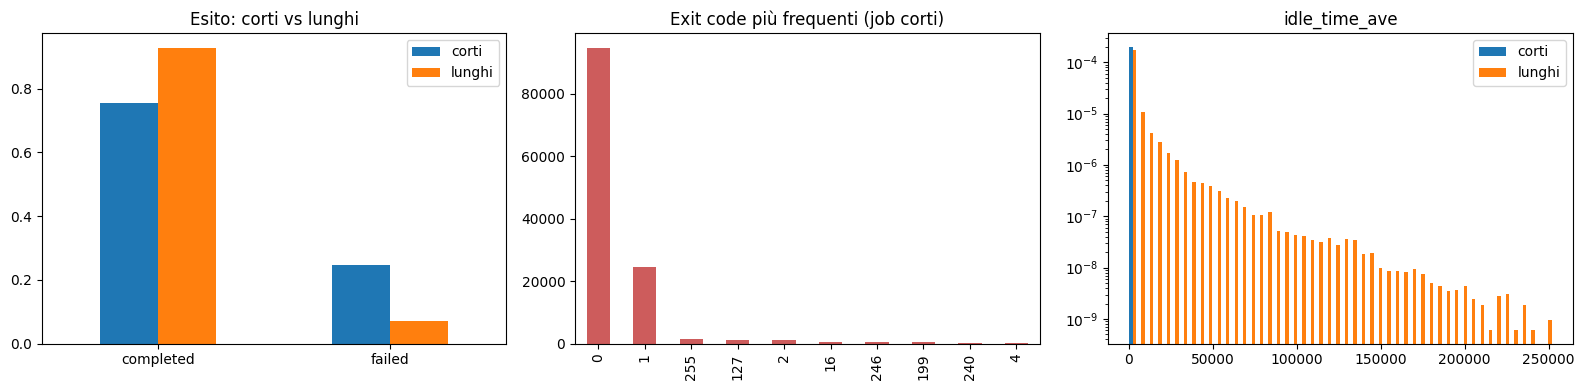

,corti,lunghi
quota failed,0.246,0.071
quota cancellati (deldt),1.000,1.000
quota nodi usati < richiesti,0.088,0.017
avgpcon medio,2662.414,5418.601
idle_time_ave medio,20.026,3173.280


In [17]:
short, longj = df[df["is_short"]], df[~df["is_short"]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
pd.concat({"corti": short["exit state"].value_counts(normalize=True),
           "lunghi": longj["exit state"].value_counts(normalize=True)}, axis=1).plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Esito: corti vs lunghi")

short["ec"].value_counts().head(10).plot.bar(ax=axes[1], color="indianred")
axes[1].set_title("Exit code più frequenti (job corti)")

axes[2].hist([short["idle_time_ave"].dropna(), longj["idle_time_ave"].dropna()], bins=50,
             label=["corti", "lunghi"], density=True, log=True)
axes[2].set_title("idle_time_ave"); axes[2].legend()
plt.tight_layout()
plt.show()

comp = pd.DataFrame({
    "corti": [short["exit state"].eq("failed").mean(), short["deldt"].notna().mean(),
              (short["nnumu"] < short["nnumr"]).mean(), short["avgpcon"].mean(), short["idle_time_ave"].mean()],
    "lunghi": [longj["exit state"].eq("failed").mean(), longj["deldt"].notna().mean(),
               (longj["nnumu"] < longj["nnumr"]).mean(), longj["avgpcon"].mean(), longj["idle_time_ave"].mean()],
}, index=["quota failed", "quota cancellati (deldt)", "quota nodi usati < richiesti",
          "avgpcon medio", "idle_time_ave medio"])
comp.round(3)

### 03.5 Analisi dei dati: correlazioni e andamento nel tempo

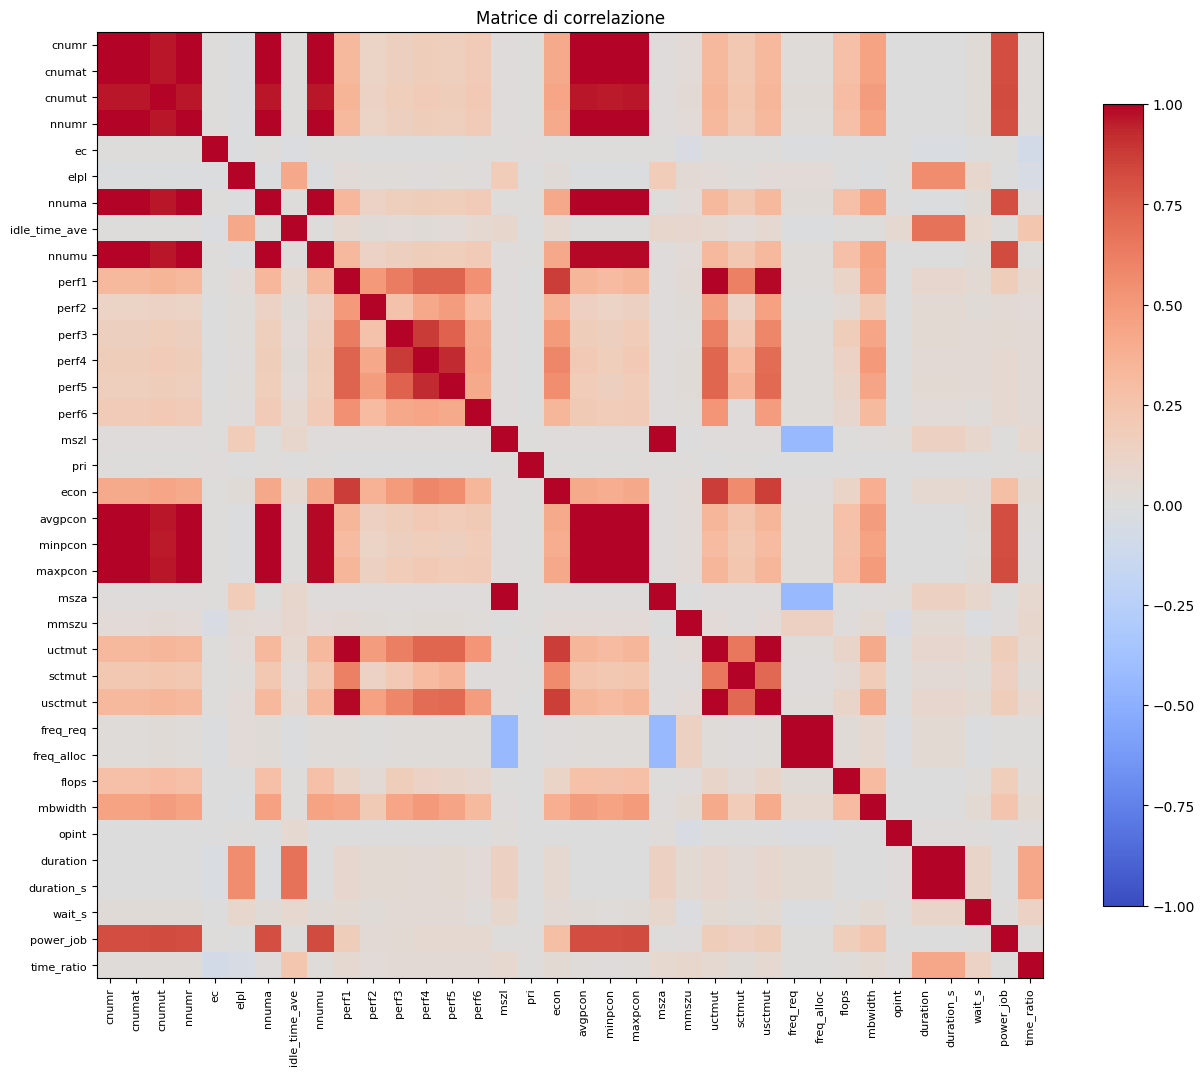

Correlazione con avgpcon (top 12 in valore assoluto):
maxpcon      0.999
minpcon      0.997
nnumr        0.996
cnumr        0.996
cnumat       0.996
nnuma        0.995
nnumu        0.992
cnumut       0.962
power_job    0.815
mbwidth      0.483
econ         0.413
perf1        0.340


In [18]:
num = df.select_dtypes("number").drop(columns=["is_short"], errors="ignore")
corr = num.corr()

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
fig.colorbar(im, ax=ax, shrink=.8)
plt.title("Matrice di correlazione")
plt.tight_layout()
plt.show()

print("Correlazione con avgpcon (top 12 in valore assoluto):")
print(corr["avgpcon"].drop("avgpcon").abs().sort_values(ascending=False).head(12).round(3).to_string())

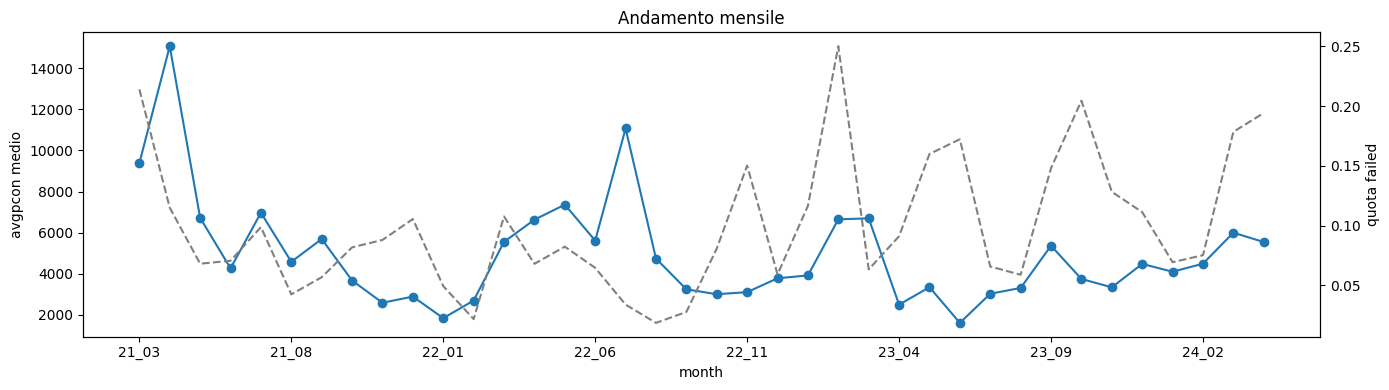

In [19]:
by_month = df.groupby("month").agg(avgpcon=("avgpcon", "mean"), failed=("exit state", lambda s: s.eq("failed").mean()))
fig, ax = plt.subplots(figsize=(14, 4))
by_month["avgpcon"].plot(ax=ax, marker="o", label="avgpcon medio")
ax.set_ylabel("avgpcon medio")
ax2 = ax.twinx()
by_month["failed"].plot(ax=ax2, color="gray", ls="--", label="quota failed")
ax2.set_ylabel("quota failed")
ax.set_title("Andamento mensile")
plt.tight_layout()
plt.show()

## Cell 04 : Dataset Preparation & Noise Canceling

**Target**: `TARGET` (default `avgpcon`, potenza media per nodo).

Rumore rimosso:
- **ID**: `jid`, `usr`, `jnam`, `jobenv_req` (identificativi anonimizzati, nessun valore numerico)
- **exit state** ed `ec`: utili in analisi, rumore per l'esperimento
- **variazione di duration**: si scartano i job con `duration` incoerente con `edt - sdt` e i job più corti di `MIN_DURATION_S`; si tiene solo `duration_s`
- colonne che contengono il target o derivano da esso (`LEAKAGE`), altrimenti il modello "barerebbe"
- colonne datetime e di servizio create nell'analisi
- valori mancanti/infiniti e code estreme del target (quantili `Q_LOW`–`Q_HIGH`)

In [20]:
TARGET = "avgpcon"
MIN_DURATION_S = 60
Q_LOW, Q_HIGH = 0.001, 0.999
TEST_SIZE = 0.30

ID_COLS = ["jid", "usr", "jnam", "jobenv_req"]
NOISE_COLS = ["exit state", "ec", "duration"]
LEAKAGE = ["econ", "minpcon", "maxpcon", "power_job"]
SERVICE_COLS = DATE_COLS + ["month", "health", "is_short", "time_ratio"]

data = df.copy()
n0 = len(data)

# variazione di duration
dur_diff = (data["duration_s"] - data["duration"]).abs()
data = data[dur_diff <= 1]
n1 = len(data)
data = data[data["duration_s"] >= MIN_DURATION_S]
n2 = len(data)

data = data.drop(columns=ID_COLS + NOISE_COLS + LEAKAGE + SERVICE_COLS, errors="ignore")
data["pclass"] = data["pclass"].map({"memory-bound": 0, "compute-bound": 1})

data = data.replace([np.inf, -np.inf], np.nan).dropna()
n3 = len(data)
lo, hi = data[TARGET].quantile([Q_LOW, Q_HIGH])
data = data[(data[TARGET] > 0) & data[TARGET].between(lo, hi)]

# colonne costanti: nessuna informazione
const = [c for c in data.columns if data[c].nunique() <= 1]
data = data.drop(columns=const)

print(f"Righe iniziali:                    {n0:,}")
print(f"- duration incoerente:             {n0 - n1:,}")
print(f"- job < {MIN_DURATION_S}s:                    {n1 - n2:,}")
print(f"- NaN / inf:                       {n2 - n3:,}")
print(f"- code del target:                 {n3 - len(data):,}")
print(f"Righe finali:                      {len(data):,}")
print("Colonne costanti rimosse:", const)

Righe iniziali:                    760,000
- duration incoerente:             10
- job < 60s:                    125,580
- NaN / inf:                       0
- code del target:                 1,270
Righe finali:                      633,140
Colonne costanti rimosse: []


In [21]:
FEATURES = [c for c in data.columns if c != TARGET]
X = data[FEATURES].astype("float32").values
y = data[TARGET].astype("float32").values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
print(f"{len(FEATURES)} feature: {FEATURES}")
print(f"Train: {X_train.shape}  Test: {X_test.shape}  ({1 - TEST_SIZE:.0%} / {TEST_SIZE:.0%})")

29 feature: ['cnumr', 'cnumat', 'cnumut', 'nnumr', 'elpl', 'nnuma', 'idle_time_ave', 'nnumu', 'perf1', 'perf2', 'perf3', 'perf4', 'perf5', 'perf6', 'mszl', 'pri', 'msza', 'mmszu', 'uctmut', 'sctmut', 'usctmut', 'freq_req', 'freq_alloc', 'flops', 'mbwidth', 'opint', 'pclass', 'duration_s', 'wait_s']
Train: (443198, 29)  Test: (189942, 29)  (70% / 30%)


## Cell 05 : Experiment 01

Quattro modelli di regressione sullo stesso split 70/30:
1. Linear Regression (con standardizzazione)
2. Decision Tree Regression
3. Random Forest Regression
4. GBT Regression (`HistGradientBoostingRegressor`, la versione di gradient boosted trees di scikit-learn adatta a centinaia di migliaia di righe)

Le predizioni sul test set finiscono in `results` e vengono valutate nella Cell 07.

In [22]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree": DecisionTreeRegressor(max_depth=20, min_samples_leaf=5, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2,
                                           max_samples=0.5, n_jobs=-1, random_state=SEED),
    "GBT": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=SEED),
}

results, fit_times = {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    fit_times[name] = time.time() - t0
    results[name] = model.predict(X_test)
    print(f"{name:18s} training {fit_times[name]:6.1f}s | R² test {r2_score(y_test, results[name]):.4f}")

Linear Regression  training    2.8s | R² test 0.9770
Decision Tree      training   22.8s | R² test 0.9886
Random Forest      training  245.4s | R² test 0.9908
GBT                training    9.5s | R² test 0.9896


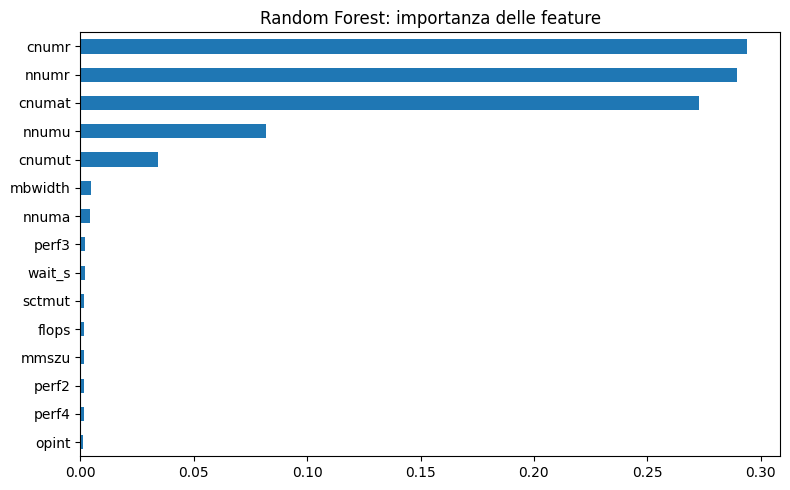

In [23]:
# Feature più importanti secondo la Random Forest
imp = pd.Series(models["Random Forest"].feature_importances_, index=FEATURES).sort_values()
imp.tail(15).plot.barh(figsize=(8, 5), title="Random Forest: importanza delle feature")
plt.tight_layout()
plt.show()

## Cell 06 : NeuralNet

Rete fully-connected con **3 hidden layer da 10 neuroni** (ReLU) e un'uscita, addestrata con **Stochastic Gradient Descent** (`torch.optim.SGD`) a mini-batch.
Usa lo stesso split 70/30 della Cell 04, così il confronto nella Cell 07 è sullo stesso test set.
Feature e target vengono standardizzati (statistiche calcolate solo sul train); le predizioni vengono riportate alla scala originale.

In [24]:
EPOCHS = 30
BATCH_SIZE = 256
LR = 0.01
MOMENTUM = 0.9   # 0.0 = SGD senza momentum
device = "cuda" if torch.cuda.is_available() else "cpu"

x_scaler = StandardScaler().fit(X_train)
y_mean, y_std = y_train.mean(), y_train.std()

def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32)

Xtr = to_tensor(x_scaler.transform(X_train))
ytr = to_tensor((y_train - y_mean) / y_std).unsqueeze(1)
Xte = to_tensor(x_scaler.transform(X_test))
yte = to_tensor((y_test - y_mean) / y_std).unsqueeze(1)

train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=BATCH_SIZE, shuffle=True)

net = nn.Sequential(
    nn.Linear(Xtr.shape[1], 10), nn.ReLU(),
    nn.Linear(10, 10), nn.ReLU(),
    nn.Linear(10, 10), nn.ReLU(),
    nn.Linear(10, 1),
).to(device)
print(net)

optimizer = torch.optim.SGD(net.parameters(), lr=LR, momentum=MOMENTUM)
loss_fn = nn.MSELoss()

Sequential(
  (0): Linear(in_features=29, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=10, bias=True)
  (3): ReLU()
  (4): Linear(in_features=10, out_features=10, bias=True)
  (5): ReLU()
  (6): Linear(in_features=10, out_features=1, bias=True)
)


In [25]:
history = {"train": [], "test": []}
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    net.train()
    running = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(net(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(xb)
    net.eval()
    with torch.no_grad():
        test_loss = loss_fn(net(Xte.to(device)), yte.to(device)).item()
    history["train"].append(running / len(Xtr))
    history["test"].append(test_loss)
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:3d} | train MSE {history['train'][-1]:.4f} | test MSE {test_loss:.4f}")
fit_times["NeuralNet (3x10, SGD)"] = time.time() - t0

with torch.no_grad():
    pred_nn = net(Xte.to(device)).cpu().numpy().ravel() * y_std + y_mean
results["NeuralNet (3x10, SGD)"] = pred_nn
print(f"\nR² test: {r2_score(y_test, pred_nn):.4f}")

plt.plot(history["train"], label="train")
plt.plot(history["test"], label="test")
plt.xlabel("epoch"); plt.ylabel("MSE (target standardizzato)")
plt.title("Curva di apprendimento")
plt.legend()
plt.show()

epoch   1 | train MSE 0.1113 | test MSE 0.1769
epoch   5 | train MSE 0.0528 | test MSE 0.0757
epoch  10 | train MSE nan | test MSE nan
epoch  15 | train MSE nan | test MSE nan


KeyboardInterrupt: 

## Cell 07 : Errors

Per ogni modello, sul test set:
- **MAE**: errore assoluto medio, e varianza dell'errore assoluto
- **MSE**: errore quadratico medio, e varianza dell'errore quadratico
- **MAPE**: errore percentuale assoluto medio, e varianza dell'errore percentuale
- varianza del residuo `y - ŷ`, RMSE, R² e tempo di training

In [ ]:
rows = []
for name, y_pred in results.items():
    e = y_test - y_pred
    ae = np.abs(e)
    se = e ** 2
    pe = ae / np.abs(y_test) * 100
    rows.append({
        "Modello": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "Var(|e|)": ae.var(),
        "MSE": mean_squared_error(y_test, y_pred),
        "Var(e²)": se.var(),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAPE %": mean_absolute_percentage_error(y_test, y_pred) * 100,
        "Var(% e)": pe.var(),
        "Var(e)": e.var(),
        "R²": r2_score(y_test, y_pred),
        "Training [s]": fit_times[name],
    })

errors = pd.DataFrame(rows).set_index("Modello").sort_values("MAE")
errors.round(4)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(axes, ["MAE", "MSE", "MAPE %"]):
    errors[m].plot.bar(ax=ax, color="steelblue", rot=30)
    ax.set_title(m)
plt.tight_layout()
plt.show()

In [ ]:
# Distribuzione dell'errore assoluto per modello
abs_err = {n: np.abs(y_test - p) for n, p in results.items()}
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(list(abs_err.values()), labels=list(abs_err.keys()), showfliers=False)
ax.set_ylabel("|errore|")
ax.set_title("Errore assoluto sul test set (senza outlier)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# Miglior modello: reale vs predetto e distribuzione dei residui
best = errors.index[0]
y_pred = results[best]
res = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].hexbin(y_test, y_pred, gridsize=60, bins="log", cmap="viridis")
axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set_xlabel(f"{TARGET} reale"); axes[0].set_ylabel(f"{TARGET} predetto")
axes[0].set_title(f"{best}: reale vs predetto")

axes[1].hist(res, bins=100, color="steelblue")
axes[1].axvline(0, color="red", lw=1)
axes[1].set_title(f"{best}: residui (media {res.mean():.3f}, var {res.var():.3f})")
plt.tight_layout()
plt.show()